# Lesson 11: Kinetics I: Potential Energy Surfaces and the Butler-Volmer Equation
Thermodynamics is based on the energy difference between starting material and product. Kinetics, and therefore the currents we actually measure, are set by the height of the barrier between them. This topic scales in complexity quickly, because it forces us to talk about potential energy surfaces. Luckily, much of electrochemistry can be described with some simplifying **assumptions**.

Today's topics:
- Potential energy surfaces and what an applied voltage does to them
- The transfer coefficient, and why it is an empirical parameter
- Deriving the Butler-Volmer equation and the standard rate constant

**Reference:**
- Sections 3.1 to 3.3 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [3]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE      # constants and the two-panel figure size
echem.use_style()                       # course-wide graph formatting

# Reaction coordinates used by the potential energy surface figures below
x_oxidized = np.linspace(0, 2, 50)
x_reduced = np.linspace(1, 3, 50)

# 1. Potential Energy Surfaces and the Applied Potential

The Butler-Volmer equation is a mathematical model for electron transfer kinetics that relies upon an assumption that is known to be incorrect. The model is accurate enough, however, that it remains as the most widely used model for studying electron transfer kinetics.

To start, we will consider the diagram that was shown in [Lesson 4](L04-Conceptual-Framework.ipynb).

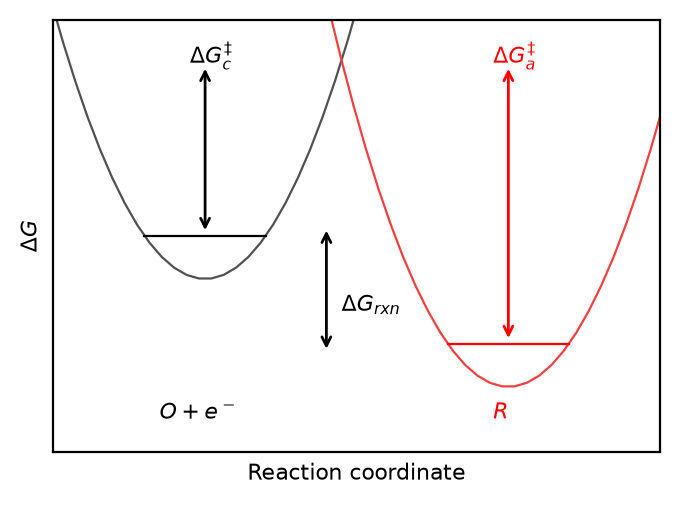

In [4]:
# Potential energy surfaces at equilibrium: the activation barriers in each direction
fig = plt.figure()
ax = plt.subplot(111)
ax.plot(x_oxidized, (x_oxidized - 1)**2 + 0.06)
ax.plot([0.8, 1.2], [0.1, 0.1], 'k')
ax.plot(x_reduced, (x_reduced - 2)**2 - 0.04)
ax.plot([1.8, 2.2], [0., 0.], 'r')
ax.set_ylim(-0.1, 0.3)
ax.set_xlim(0.5, 2.5)
ax.set_ylabel(r'$\Delta G$')
ax.set_xlabel('Reaction coordinate')
ax.set_xticks([])
ax.set_yticks([])

ax.annotate(r'$O + e^-$', (0.85, -0.07), fontsize=8)
ax.annotate(r'$R$', (1.95, -0.07), color="red", fontsize=8)
ax.annotate(r'$\Delta G_{rxn}$', (1.45, 0.03), fontsize=8, color='black')
ax.annotate(r'$\Delta G_{c}^\ddag$', (0.95, 0.26), fontsize=8, color='black')
ax.annotate(r'$\Delta G_{a}^\ddag$', (1.95, 0.26), fontsize=8, color='red')

for xy, xytext, c in [((1.4, 0.11), (1.4, -0.01), 'black'),
                      ((1.0, 0.10), (1.0, 0.26), 'black'),
                      ((2.0, 0.00), (2.0, 0.26), 'red')]:
    ax.annotate('', xy=xy, xycoords='data', xytext=xytext, textcoords='data',
                fontsize=8, arrowprops=dict(arrowstyle='<->', color=c))

fig.savefig('../workspace/reactioncoordinate-kinetics.png')

[Lesson 9](L09-Thermodynamics-I.ipynb) introduced the idea that application of a voltage to an electrode results in a shift in thermodynamics for the reaction. Quantitatively, the changes are captured by the Nernst equation:

$
\large E = E^{0'} - \frac{RT}{nF}ln\left[\frac{[R]}{[O]}\right]
$

Lets explore the implications of this behavior on the potential energy surfaces for the electrochemical reaction using arbitrary curves:

In [5]:
@interact(offset=widgets.FloatSlider(value=0.000, min=-0.10, max=0.10, step=0.005,
                                    readout_format=".3f", description=r'$E_{applied}$'))
def plot_applied_potential(offset):
    '''Move the reduced-state surface up or down and watch both barriers respond.'''
    fig = plt.figure()
    ax = plt.subplot(111)
    ax.set_ylim(-0.15, 0.36)
    ax.set_xlim(0.5, 2.5)
    ax.set_ylabel(r'Energy')
    ax.set_xlabel('Reaction coordinate')
    ax.set_xticks([])
    ax.set_yticks([])

    ax.annotate(r'$O + e^-$', (0.85, -0.14), fontsize=6)
    ax.plot(x_oxidized, (x_oxidized - 1)**2, 'black')
    ax.plot(x_reduced, (x_reduced - 2)**2, 'k')

    ax.annotate(r'$R$', (1.95, -0.14), color="black", fontsize=6)
    ax.plot(x_oxidized, (x_oxidized - 1)**2 - offset, 'red')

    x_int = (3 + offset)/2
    y_int = (x_int - 2)**2
    ax.scatter([x_int], [y_int], s=10)
    r_base = 0.
    o_base = -offset
    g_c = (y_int - o_base)*F/1000       # kJ/mol
    g_a = (y_int - r_base)*F/1000
    g_rxn = offset*F/1000

    ax.annotate(rf'$\Delta G = ${g_rxn:6.2f} kJ/mol', (1.4, -0.05), fontsize=6, color='blue')
    ax.annotate('', xy=(1.5, y_int - 0.5*offset), xycoords='data',
                xytext=(1.5, y_int + 0.5*offset), textcoords='data',
                fontsize=6, arrowprops=dict(arrowstyle='<->', color='blue'))

    ax.annotate(rf'$\Delta G_{{c}}^\ddag$ = {g_c:6.2f} kJ/mol', (0.65, 0.32), fontsize=6, color='black')
    ax.annotate('', xy=(1, -offset), xycoords='data', xytext=(1, y_int), textcoords='data',
                fontsize=6, arrowprops=dict(arrowstyle='<->', color='black'))

    ax.annotate(rf'$\Delta G_{{a}}^\ddag$ = {g_a:6.2f} kJ/mol', (1.7, 0.32), fontsize=6, color='black')
    ax.annotate('', xy=(2, r_base), xycoords='data', xytext=(2, y_int), textcoords='data',
                fontsize=6, arrowprops=dict(arrowstyle='<->', color='black'))

interactive(children=(FloatSlider(value=0.0, description='$E_{applied}$', max=0.1, min=-0.1, readout_format='.…

The potential energy surface (PES) curves exhibit a vertical motion upon changes in $E$ . The concepts underlying several aspects of this figure need to be formalized before developing the Butler-Volmer equation:

1. **Potential Energy Surfaces**. Applying a voltage results in a change in energy between two arbitrary $E$ values, which can be defined using the relationship between Gibbs energy and voltage:

 $ \large \Delta G(E_1, E_2) = -nF \Delta E$ 

 
2. **Number of electrons**. Electron transfer theories are based upon elementary steps, which by definition can **only ever** contain a single electron transfer. Therefore, all kinetic models are inherently limited to:

 $\large n = 1.0$ 
 
3. **Activation Energy**. The shift in PES location due to $E_{applied}$ is therefore limited to: 

 $\large \Delta G(E) = -F(E - E^{0'})$ 
 


<div class="alert alert-block alert-info">
<b>Activity:</b> Inspection of the diagram above indicates that the total energy change must be somehow split between the two different activation energy values. Manipulate the diagram above and study the relationship that $E_{applied}$ has on $\Delta G^\ddagger_c$ and $\Delta G^\ddagger_a$ . 
<br>
 Without peeking below, can you propose a mathematical relationship to handle changes in kinetic parameters?
<br>
 Use the cell below to test your proposal.
</div>

In [ ]:
@interact(offset=widgets.FloatSlider(value=0.000, min=-0.10, max=0.10, step=0.005,
                                     readout_format=".3f", description=r'$E_{applied}$'),
          linearise=widgets.Checkbox(value=False, description='linearise the surfaces'))
def plot_energy_split(offset, linearise):
    '''How the applied energy divides between the two activation barriers.

    Left panel zooms on the crossing point; right panel shows the whole picture.
    Leave the box unticked for the true (parabolic) surfaces.  Tick it to make
    the Butler-Volmer approximation, replacing each well with a straight line.
    The difference between those two states is the entire content of Section 2.
    '''
    if linearise:
        y_oxidized = x_oxidized/2
        y_reduced = 1.5 - x_reduced/2
        y_shifted = x_oxidized/2 - offset
        r_base, o_base = 0.5, 0.5 - offset
        x_int_0, y_int_0 = 1.5, 0.75
        x_int = 1.5 - offset
        y_int = x_int/2
        zoom_ylim, label_y, base_y = (0.6, 0.9), 0.88, 0.61
    else:
        y_oxidized = (x_oxidized - 1)**2
        y_reduced = (x_reduced - 2)**2
        y_shifted = (x_oxidized - 1)**2 - offset
        r_base, o_base = 0.0, -offset
        x_int_0, y_int_0 = 1.5, 0.25
        x_int = (3 + offset)/2
        y_int = (x_int - 2)**2
        zoom_ylim, label_y, base_y = (0.12, 0.37), 0.36, 0.125

    g_0 = (y_int_0 - r_base)*F/1000                 # kJ/mol
    g_c = (y_int - o_base)*F/1000
    g_a = (y_int - r_base)*F/1000
    gg_c, gg_a = g_c - g_0, g_a - g_0
    g_rxn = -offset*F/1000

    fig = plt.figure(figsize=WIDE)
    ax1 = plt.subplot(121)
    ax2 = plt.subplot(122)
    ax1.set_ylim(*zoom_ylim)
    ax1.set_xlim(1.25, 1.75)
    ax1.set_ylabel(r'Energy')

    for ax in [ax1, ax2]:
        ax.set_xlabel('Reaction coordinate')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.plot(x_oxidized, y_oxidized, 'black')
        ax.plot(x_reduced, y_reduced, 'k')
        ax.plot(x_oxidized, y_shifted, 'red')

    ax1.annotate(r'$O + e^-$', (1.25, base_y), fontsize=8)
    ax1.annotate(r'$R$', (1.735, base_y), color='black', fontsize=8)
    ax1.annotate(rf'$\Delta G_{{c}}^\ddag$ = {g_c:6.2f} kJ/mol', (1.255, label_y), fontsize=6)
    ax1.annotate(rf'$\Delta G_{{a}}^\ddag$ = {g_a:6.2f} kJ/mol', (1.61, label_y), fontsize=6)
    ax1.annotate(rf'$\Delta G_{{total}} = ${g_rxn:6.2f} kJ/mol', (1.43, label_y),
                 fontsize=6, color='blue')

    for y in [y_int_0, y_int]:
        ax1.axhline(y, xmin=0.3, xmax=0.7, linestyle=':')

    if gg_c >= 0:
        anodic_label_y, cathodic_label_y = y_int + offset*0.25, y_int - offset*0.25
    else:
        anodic_label_y, cathodic_label_y = y_int - offset*0.25, y_int + offset*0.25

    ax1.annotate(rf'$\Delta \Delta G^\ddag_{{a}} = ${gg_a:6.2f} kJ/mol',
                 (1.6, anodic_label_y), fontsize=6, color='blue')
    ax1.annotate('', xy=(1.58, y_int_0), xycoords='data', xytext=(1.58, y_int),
                 textcoords='data', arrowprops=dict(arrowstyle='<->', color='blue'))
    ax1.annotate(rf'$\Delta \Delta G^\ddag_{{c}} = ${gg_c:6.2f} kJ/mol',
                 (1.26, cathodic_label_y), fontsize=6, color='blue')
    ax1.annotate('', xy=(1.42, y_int_0), xycoords='data', xytext=(1.42, y_int),
                 textcoords='data', arrowprops=dict(arrowstyle='<->', color='blue'))

    if linearise:
        ax2.set_ylim(-0.1, 1.1)
        ax2.set_xlim(0, 3)
        ax2.annotate(r'$O + e^-$', (0.85, 0.0), fontsize=6)
        ax2.annotate(r'$R$', (1.95, 0.0), color='black', fontsize=6)
    else:
        ax2.set_ylim(-0.15, 0.36)
        ax2.set_xlim(0.5, 2.5)
        ax2.annotate(r'$O + e^-$', (0.85, -0.14), fontsize=6)
        ax2.annotate(r'$R$', (1.95, -0.14), color='black', fontsize=6)

interactive(children=(FloatSlider(value=0.0, description='$E_{applied}$', max=0.1, min=-0.1, readout_format='.…

A few observations in the figure above make it apparent that the energy split between $\Delta G^\ddagger_c$ and $\Delta G^\ddagger_a$ is non-trivial.
- The total energy is split between the two activation energies; one positive and one negative
- For low $E-E^{0'}$ , the split is roughly 50% to each
- Beyond $E-E^{0'}$ =15 mV the energy split becomes unequal, becoming more pronounced as $E_{applied}$ grows

# 2. The Butler-Volmer Approximation

The unequal separation of energy between the activation energies as $E_{applied}$ grows arises due to the non-linear nature of PES. Our parabolic approximations here are shallow near their minimum, but become increasingly steep as one moves away from the minimum. Assuming symmetric PES for the two states, the $E^{0'}$ situation places the intercept directly in the center of the two curves. Movement of one curve relative to another pushes this intercept towards one of the curves. This effectively *increases* the slope in the vicinity of the intercept for one PES, but *decreases* the slope for the other. This causes the inequality that we see above.

We could mathematically correct for this if we knew the equation for each of the PES curves. Experimentally, we typically do not have this information. In modern times, we are spoiled and can calculate these curves through density functional theory calculations. Historically, this was not possible. The first successful consideration of this problem therefore relied upon a simplification. This simplification continues to be used to this day.

The Butler-Volmer approach was to:
1. ignore the curvature in the PES, effectively approximating the PES to be two linear plots intercepting with each other
2. assume that the energy is always split between $\Delta G^\ddagger_a$ and $\Delta G^\ddagger_c$ in some consistent fashion

**Go back to the figure above and tick the `linearise the surfaces` box.** Sweep $E_{applied}$ again and watch what the approximation buys: the energy now divides in a fixed ratio no matter how hard you drive the reaction. That fixed ratio needs a name, and it is called the **transfer coefficient** ( $\alpha$ ).

<div class="alert alert-block alert-success">
 <b>Transfer coefficient ( $\alpha$ ):</b> An <i>empirical term</i> signifying what fraction of the energy goes to adjust $\Delta G^\ddagger_c$ .
<br>
Being a fraction, values are only physically realistic in the range of 0 to 1.
<br>
Values are typically assumed to be 0.5.
<br>
Values have been experimentally measured between ~0.3 and ~0.7.
</div>

Mathematically, the Butler-Volmer approach indicates:

$
\large \Delta G^\ddagger_c = \Delta G^\ddagger_{0,c} + \alpha F(E-E^{0'})
$

$
\large \Delta G^\ddagger_a = \Delta G^\ddagger_{0,a} - (1-\alpha)F(E-E^{0'})
$

Where $\Delta G^\ddagger_{0,c}$ and $\Delta G^\ddagger_{0,a}$ are the activation energies at $E^{0'}$ .

# 3. From Barriers to Currents

It is important to understand the assumptions underlying this approach, and the limitations that they impose. However, the power of this technique is that it provides a simple means to analyze experimental data for which little chemical information is known. Starting from the basic kinetics equation introduced in [Lesson 4](L04-Conceptual-Framework.ipynb) for the generic electrochemical reaction:

$
\large i_j = nFAk_jC_j(0,t)
$

We can recognize that all currents are additive, including the anodic and cathodic components of a single reaction:

$
\large i = i_a - i_c
$

<div class="alert alert-block alert-success">
 <b>Sign convention:</b> This course uses the modern (IUPAC) convention throughout: <b>anodic (oxidation) currents are positive</b> and cathodic (reduction) currents are negative. Writing the anodic term first is what keeps every equation that follows consistent with that choice.
 <br>
 Be aware that many textbooks -- including Bard &amp; Faulkner -- derive these same equations with the cathodic term first, and so report currents of the opposite sign. The chemistry is identical; only the sign of $i$ changes. Check the convention before comparing an equation or a figure to one of ours.
</div>

Therefore, with the necessary $n=1$ :

$
\large i = FA[k_aC_R(0,t) - k_cC_O(0,t)]
$

We can use the Arrhenius equation to define $k_j$ :

$
\large k_j = A_j e^{\frac{-\Delta G^\ddagger_j}{RT}}
$

Using the equations derived from the Butler-Volmer approach, we can substitute $\Delta G^\ddagger_j$ for the anodic and cathodic portions:

$
\large k_c = \left[ A_c e^{-\Delta G^\ddagger_{0,c}/RT} \right] e^{-\alpha F(E-E^{0'})/RT}
$

$
\large k_a = \left[ A_a e^{-\Delta G^\ddagger_{0,a}/RT} \right] e^{(1-\alpha)F(E-E^{0'})/RT}
$

Notice the shape of these. Each rate constant is a constant group in square brackets, multiplied by an exponential in potential. **That is the whole of electrochemical kinetics in one line:** a chemical term you cannot change from the outside, and a term you control with a dial on the potentiostat.

Here, it is useful to define a special condition:

 $\large E = E^{0'}$ 

 $\large C_O^* = C_R^*$ 

Where the $C_j^*$ terms denote bulk solution concentration. Under these situations:

 $\large k_a = k_c = k^0$ 

<div class="alert alert-block alert-success">
 <b>Standard rate constant ( $k^0$ ):</b> Rate constant for an electrochemical reaction at standard equilibrium.
 <br>
 Measured values span a huge range: ~10 $^1$ to ~10 $^{-9}$ cm s $^{-1}$ 
</div>

<div class="alert alert-block alert-danger">
<b>Check your units!</b>
<br>
 $k^0$ is quoted in cm s $^{-1}$ , but a homogeneous first-order rate constant is in s $^{-1}$ . Where did the length come from?
<br>
Work it back from $i = FAk^0C$ , and be ready to explain the answer to a physical chemist who has never made a surface measurement.
</div>

This special $k^0$ value is equivalent to the group of terms inside the square brackets above (check it!). Therefore:

$
\large k_c = k^0 e^{\frac{-\alpha F(E-E^{0'})}{RT}}
$

$
\large k_a = k^0 e^{\frac{(1-\alpha)F(E-E^{0'})}{RT}}
$

These two values can be substituted into the equation describing total the current from above to yield the **Butler-Volmer equation**:

$
\large i = F A k^0 \left[ C_R(0,t)e^{(1-\alpha) F (E-E^{0'}) / R T} - C_O(0,t)e^{-\alpha F (E-E^{0'}) / R T} \right]
$

This equation contains terms that represent the most important fundamental considerations for electrochemical experiments:
1. kinetics: $k^0$ 
2. thermodynamics: $E-E^{0'}$ 
3. mass transfer: $C_i(0,t)$ 

An important part of the above discussion is the realization that: 
- **rate constants are not constant**
- **standard rate constants ARE constant**

<div class="alert alert-block alert-info">
<b>Activity:</b> The standard rate constant $k^0$ was defined under one very specific set of conditions.
<br>
State those conditions, then explain in two sentences why $k^0$ is a constant while $k_a$ and $k_c$ are not.
</div>

- Conditions defining $k^0$ : ANSWER
- Why $k^0$ is constant and the others are not: ANSWER

# 4. Marcus Theory: Keeping the Curvature

While potential energy surfaces are approximately parabolic in nature, Section 2 threw the curvature away to simply the algebra. That was a historical solution that continues to be applied, but it cost us something specific: $\alpha$ became an empirical number that we measure rather than a quantity we can predict.

More advanced electron transfer theories do exist, such as Marcus theory. Marcus theory maintains the parabolic PES structure, with the reactant well at $x=0$ and the product well at $x=1$ on a reaction coordinate. We can define these, using the same curvature $\lambda$ , and offset the product well by the driving force:

 $ \large G_O(x) = \lambda x^2 \qquad\qquad G_R(x) = \lambda (x-1)^2 + \Delta G^\circ $ 

<div class="alert alert-block alert-success">
<b>Reorganization energy ( $\lambda$ )</b>: the energy it would cost to distort the reactant, and the solvent around it, into the geometry of the product <b>without</b> transferring the electron. Typically 0.5 to 1.5 eV in water.
</div>

If we set the two PES equations as equal, we find where they cross:

 $ \large \lambda x^2 = \lambda(x-1)^2 + \Delta G^\circ \quad\Longrightarrow\quad x^\ddagger = \frac{\lambda + \Delta G^\circ}{2\lambda} $ 

Substituting back gives the barrier:

 $ \large \Delta G^\ddagger = \frac{(\lambda + \Delta G^\circ)^2}{4\lambda} $ 

And here is the payoff. Differentiate the barrier with respect to the driving force, which is the definition of the transfer coefficient from Section 2:

 $ \large \alpha = \frac{\partial \Delta G^\ddagger}{\partial \Delta G^\circ} = \frac{1}{2} + \frac{\Delta G^\circ}{2\lambda} = x^\ddagger $ 

**The transfer coefficient is the position of the transition state along the reaction coordinate.** It was never a fudge factor. It is a coordinate, and it moves when you change the potential.

In [ ]:
@interact(reorg=widgets.FloatSlider(value=0.80, min=0.30, max=1.50, step=0.05,
                                    description=r'$\lambda$ /eV'),
          driving_force=widgets.FloatSlider(value=0.00, min=-1.40, max=0.40, step=0.05,
                                            description=r'$\Delta G^\circ$ /eV'))
def plot_marcus(reorg, driving_force):
    '''Left: the two parabolas and their crossing point.  Right: alpha vs driving force.

    The crossing point on the left sits at exactly the alpha marked on the right.
    Drive the reaction hard enough (dG below -lambda) and the barrier reappears:
    the Marcus inverted region, which Butler-Volmer cannot describe at all.
    '''
    x = np.linspace(-0.4, 1.4, 400)
    g_oxidized, g_reduced = echem.marcus_surfaces(x, reorg, driving_force)

    x_cross = (reorg + driving_force)/(2*reorg)
    barrier = echem.marcus_barrier(driving_force, reorg)
    alpha = echem.marcus_alpha(driving_force, reorg)

    fig = plt.figure(figsize=WIDE)
    ax1 = plt.subplot(121)
    ax2 = plt.subplot(122)

    ax1.plot(x, g_oxidized, color='black', label=r'$O + e^-$')
    ax1.plot(x, g_reduced, color='darkred', label=r'$R$')
    ax1.scatter([x_cross], [reorg*x_cross**2], s=12, color='blue', zorder=5)
    ax1.axvline(x_cross, linestyle=':', color='blue')
    ax1.set_xlabel('Reaction coordinate')
    ax1.set_ylabel(r'$G$ /eV')
    ax1.set_ylim(-1.6, 1.6)
    ax1.legend(fontsize=6, loc=1)

    potentials = np.linspace(-1.4, 0.4, 300)
    ax2.plot(potentials, echem.marcus_alpha(potentials, reorg), color='darkred')
    ax2.axhline(0.5, linestyle='--', color='gray')
    ax2.axhspan(0.3, 0.7, color='gray', alpha=0.15)
    ax2.scatter([driving_force], [alpha], s=12, color='blue', zorder=5)
    ax2.set_xlabel(r'$\Delta G^\circ$ /eV')
    ax2.set_ylabel(r'$\alpha$')
    ax2.axhline(0.0, color='black', linewidth=0.6)
    ax2.set_ylim(-0.4, 1.0)

    print(f'crossing at x = {x_cross:.3f}     alpha = {alpha:.3f}     '
          f'barrier = {barrier:.4f} eV')

interactive(children=(FloatSlider(value=0.8, description='$\\lambda$ /eV', max=1.5, min=0.3, step=0.05), Float…

**Three important things** to note: 

First, this shows why the Butler-Volmer approximation has survived a century of use and is often quite accurate. The dashed line and the shaded band on the right are the Butler-Volmer assumption ( $\alpha = 0.5$ ) and the experimentally reported range (roughly 0.3 to 0.7) from Section 2. Marcus theory explains both at once: $\alpha$ **is** exactly 0.5 at $\Delta G^\circ = 0$ (*at least, it is when the PES are symmetric*), and it drifts away linearly at a rate set by $1/2\lambda$ . A reaction with a large reorganization energy holds $\alpha$ near 0.5 over a wide window.

Second, the barrier vanishes entirely at $\Delta G^\circ = -\lambda$ . The reaction has become **barrierless**, and $\alpha$ has reached zero. Applying a larger overpotential cannot speed it up any further.

Third, push past that point and the barrier **comes back**, and $\alpha$ goes *negative*. A negative transfer coefficient is not a mistake in the algebra. There exists ongoing debates regarding the **Marcus inverted region** in electrochemical measurements.

<div class="alert alert-block alert-danger">
<b>Question:</b> Set $\lambda$ = 0.8 eV and slide $\Delta G^\circ$ down to $-1.2$ eV.
<br>
The reaction is now more thermodynamically favourable than it was at $-0.8$ eV, yet it is slower. Look at the left panel and articulate to your neighbour why, in terms of where the two parabolas cross.
</div>

That last region is the **Marcus inverted region**, and it is one of the few predictions in physical chemistry that was disbelieved for decades before being confirmed. It cannot be produced by the Butler-Volmer treatment at all, for a simple reason: a straight line has no minimum, so a linearised surface can never make a barrier come back.

<div class="alert alert-block alert-success">
Butler-Volmer is not wrong so much as it is <b>local</b>. It is the tangent to Marcus theory at $\Delta G^\circ = 0$ , and it is reliable as long as that tangent is.
</div>

So why does this course keep using Butler-Volmer? Because $\lambda$ is rarely known for a real electrode reaction, most electrochemistry is done within a few hundred millivolts of $E^{0'}$ where the tangent is excellent, and the inverted region is very difficult to reach at an electrode: a metal has a continuum of electron energies, so there is almost always an occupied level at the right energy to keep the rate up. **It is largely a molecular phenomenon, and it is why the confirmation came from homogeneous chemistry rather than from an electrode.**